# Time Series Forecasting: Naive Baselines, Statistical Models and XGBoost with Calendar Covariates

Daily sales forecasting for one store–item series (store 1, item 1) from the Kaggle *Store Item Demand Forecasting* dataset, 2013–2017.

**What this notebook does**

1. Exploratory analysis: trend, weekly and yearly seasonality.
2. A leakage-free split: train (2013-01 → 2017-06), validation (2017-07 → 2017-09) for tuning, test (2017-10 → 2017-12) touched once at the end.
3. Benchmarks every model on the same 92-day test window: seasonal naive, naive drift, exponential smoothing (ETS), AutoARIMA and tuned XGBoost.
4. Rolling-origin backtest with retraining over 12 monthly windows.
5. SHAP explanation of the final XGBoost model.
6. Refits the final model on the full history and saves it for the Streamlit app, which forecasts beyond the end of the data.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

from darts.models import NaiveSeasonal, NaiveDrift, ExponentialSmoothing, AutoARIMA, XGBModel
from darts.metrics import mae, mape
from darts.utils.statistics import check_seasonality
from darts.explainability import ShapExplainer

from utils import load_series, make_calendar_covariates, make_xgb, fit_eval_model, grid_search_xgb

STORE, ITEM = 1, 1
VAL_START, TEST_START = "2017-07-01", "2017-10-01"   # 92-day validation and test windows
SEED = 42
plt.rcParams["figure.figsize"] = (13, 4)

Support for PyTorch based likelihood models not available. To enable them, install "darts[torch]" or "darts[all]" (with pip); or "u8darts-torch" or "u8darts-all" (with conda).


Support for Torch based models not available. To enable them, install "darts[torch]" or "darts[all]" (with pip); or "u8darts-torch" or "u8darts-all" (with conda).


Support for Torch based explainers not available. To enable them, install "darts[torch]" or "darts[all]" (with pip); or "u8darts-torch" or "u8darts-all" (with conda).


## 2. Exploratory analysis

1826 daily observations, 2013-01-01 to 2017-12-31


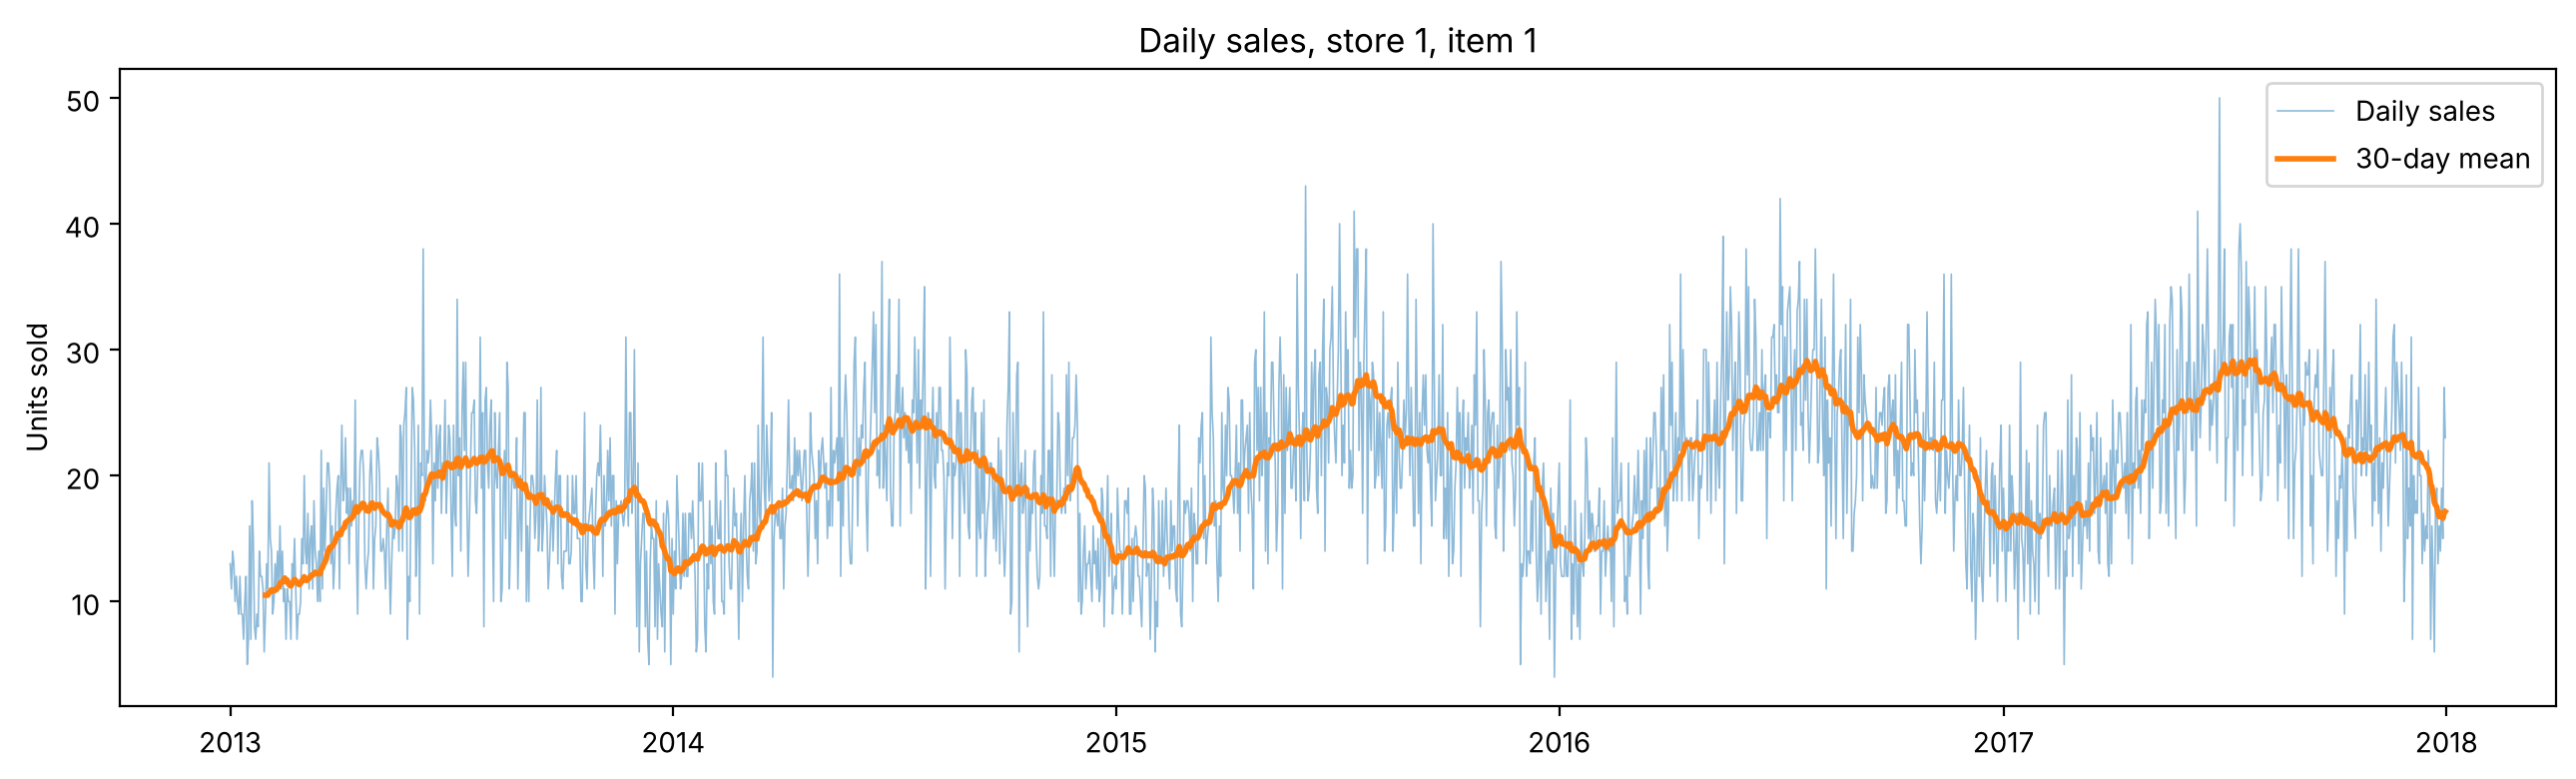

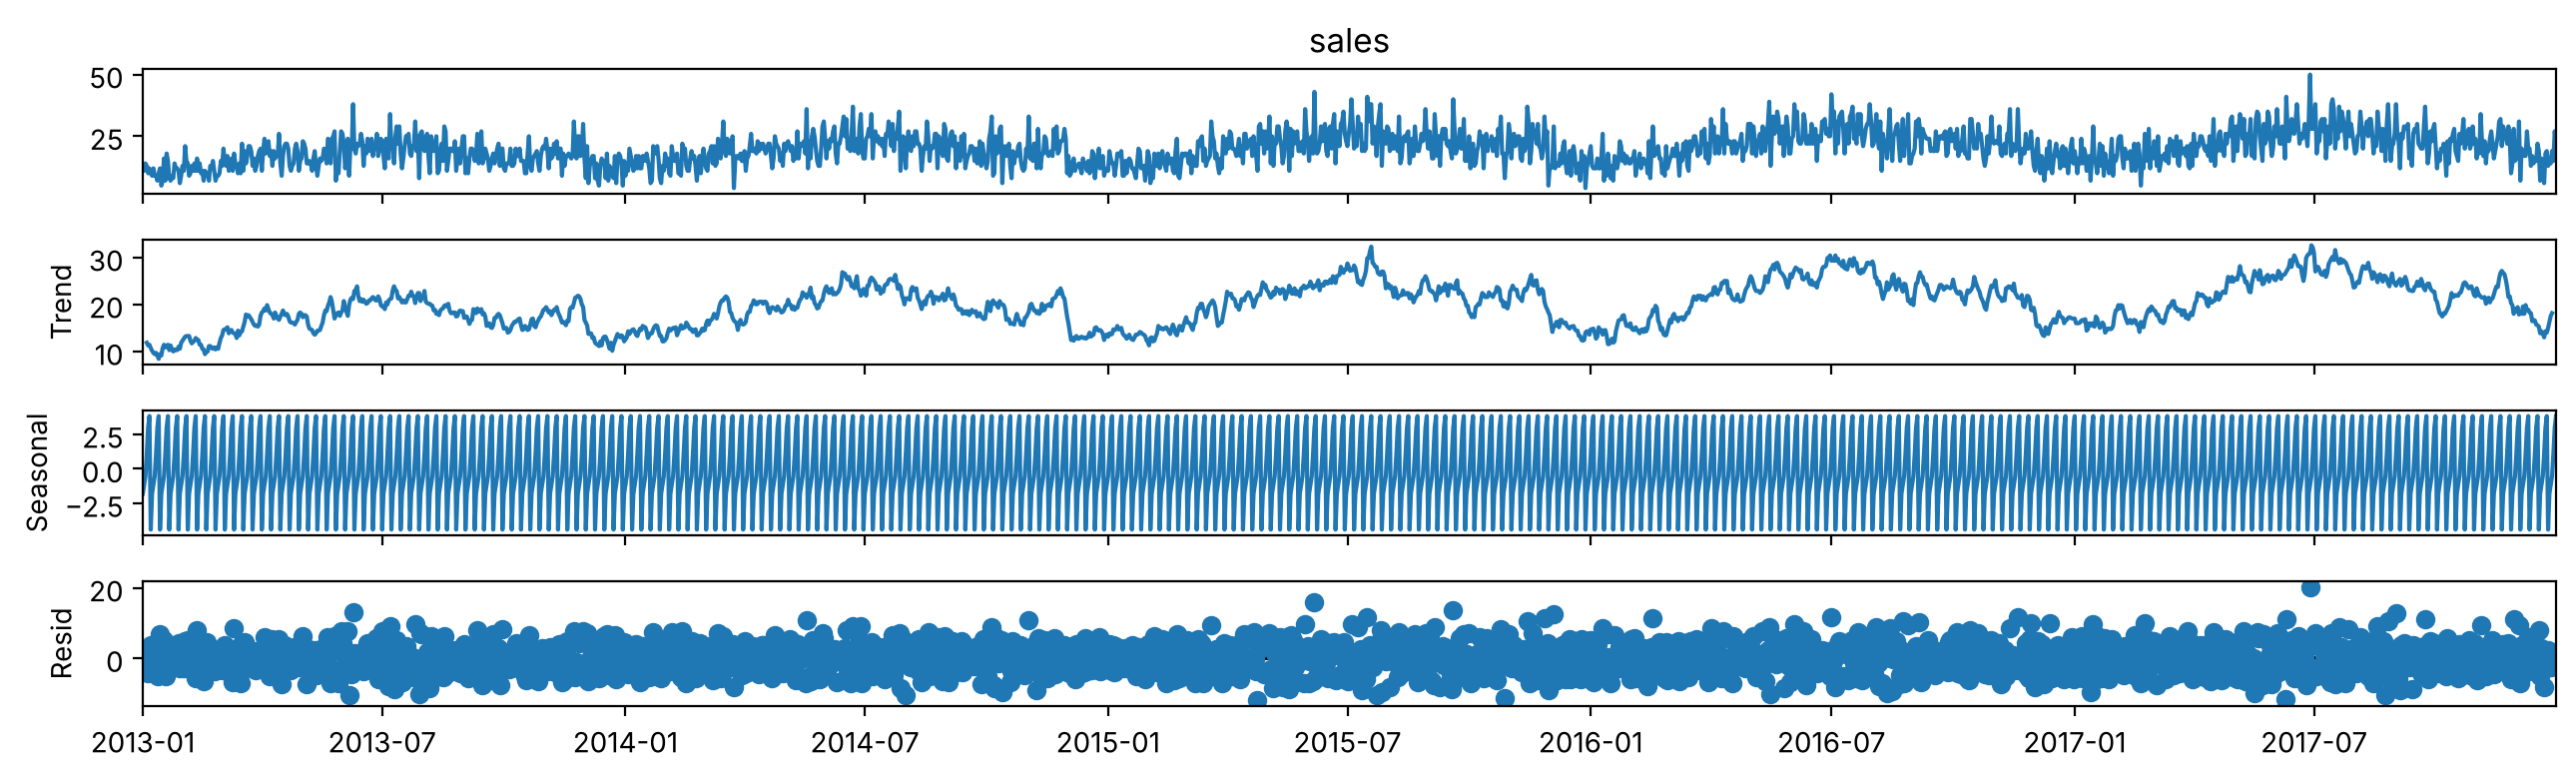

Weekly seasonality (period 7) significant: True


In [2]:
series = load_series("data/train.csv", store=STORE, item=ITEM)
print(f"{len(series)} daily observations, {series.start_time().date()} to {series.end_time().date()}")

s = series.to_series()
fig, ax = plt.subplots()
ax.plot(s.index, s.values, lw=0.6, alpha=0.5, label="Daily sales")
ax.plot(s.index, s.rolling(30).mean(), lw=2, label="30-day mean")
ax.set_title(f"Daily sales, store {STORE}, item {ITEM}"); ax.set_ylabel("Units sold"); ax.legend()
plt.tight_layout(); plt.savefig("images/demand_dynamics.png", dpi=120); plt.show()

seasonal_decompose(s, model="additive", period=7).plot(); plt.show()

is_weekly, _ = check_seasonality(series, m=7, alpha=0.05)
print(f"Weekly seasonality (period 7) significant: {is_weekly}")

## 3. Train / validation / test split and covariates

Hyperparameters are chosen on the validation window only. The test window is used once, for the final comparison, with every model refitted on train + validation.
Calendar features (cyclical day-of-week and month, weekend flag) are known in advance, so they enter XGBoost as **future covariates**.

In [3]:
train_val, test = series.split_before(pd.Timestamp(TEST_START))
train, val = train_val.split_before(pd.Timestamp(VAL_START))
print(f"train {len(train)} days | validation {len(val)} days | test {len(test)} days")

covariates = make_calendar_covariates(series.start_time(), series.end_time() + pd.Timedelta(days=120))

train 1642 days | validation 92 days | test 92 days


## 4. Tune XGBoost on the validation window

In [4]:
param_grid = {
    "lags": [7, 14, 28],
    "n_estimators": [100, 200, 400],
    "max_depth": [3, 6],
    "learning_rate": [0.05, 0.1],
}
best_params, grid_results = grid_search_xgb(train, val, covariates, param_grid)
grid_results.head(5)

Tested 36 combinations. Best validation MAE: 3.898 with {'lags': 28, 'n_estimators': 400, 'max_depth': 6, 'learning_rate': 0.05}


,lags,n_estimators,max_depth,learning_rate,val_MAE
0,28,400,6,0.05,3.897934
1,28,100,6,0.05,3.917959
2,14,400,3,0.05,3.921412
3,14,100,3,0.10,3.935298
4,28,400,3,0.05,3.952401


## 5. Final comparison on the held-out test window

In [5]:
models = {
    "Seasonal naive (7)": (NaiveSeasonal(K=7), None),
    "Naive drift": (NaiveDrift(), None),
    "ETS": (ExponentialSmoothing(seasonal_periods=7), None),
    "AutoARIMA": (AutoARIMA(season_length=7), None),
    "XGBoost (tuned)": (make_xgb(best_params, random_state=SEED), covariates),
}
rows, forecasts = [], {}
for name, (model, cov) in models.items():
    m_mae, m_mape, fc = fit_eval_model(model, name, train_val, test, future_covariates=cov)
    rows.append({"model": name, "MAE": m_mae, "MAPE_%": m_mape})
    forecasts[name] = fc

results = pd.DataFrame(rows).set_index("model").sort_values("MAE")
base = results.loc["Seasonal naive (7)", "MAE"]
results["MAE_vs_seasonal_naive_%"] = (results["MAE"] / base - 1) * 100
results.round(2)

Seasonal naive (7)     MAE:  6.120   MAPE:  38.17%
Naive drift            MAE: 10.398   MAPE:  68.74%


ETS                    MAE:  5.707   MAPE:  39.01%


AutoARIMA              MAE:  5.921   MAPE:  40.56%


XGBoost (tuned)        MAE:  4.151   MAPE:  23.38%


,MAE,MAPE_%,MAE_vs_seasonal_naive_%
model,,,
XGBoost (tuned),4.15,23.38,-32.17
ETS,5.71,39.01,-6.75
AutoARIMA,5.92,40.56,-3.24
Seasonal naive (7),6.12,38.17,0.00
Naive drift,10.40,68.74,69.92


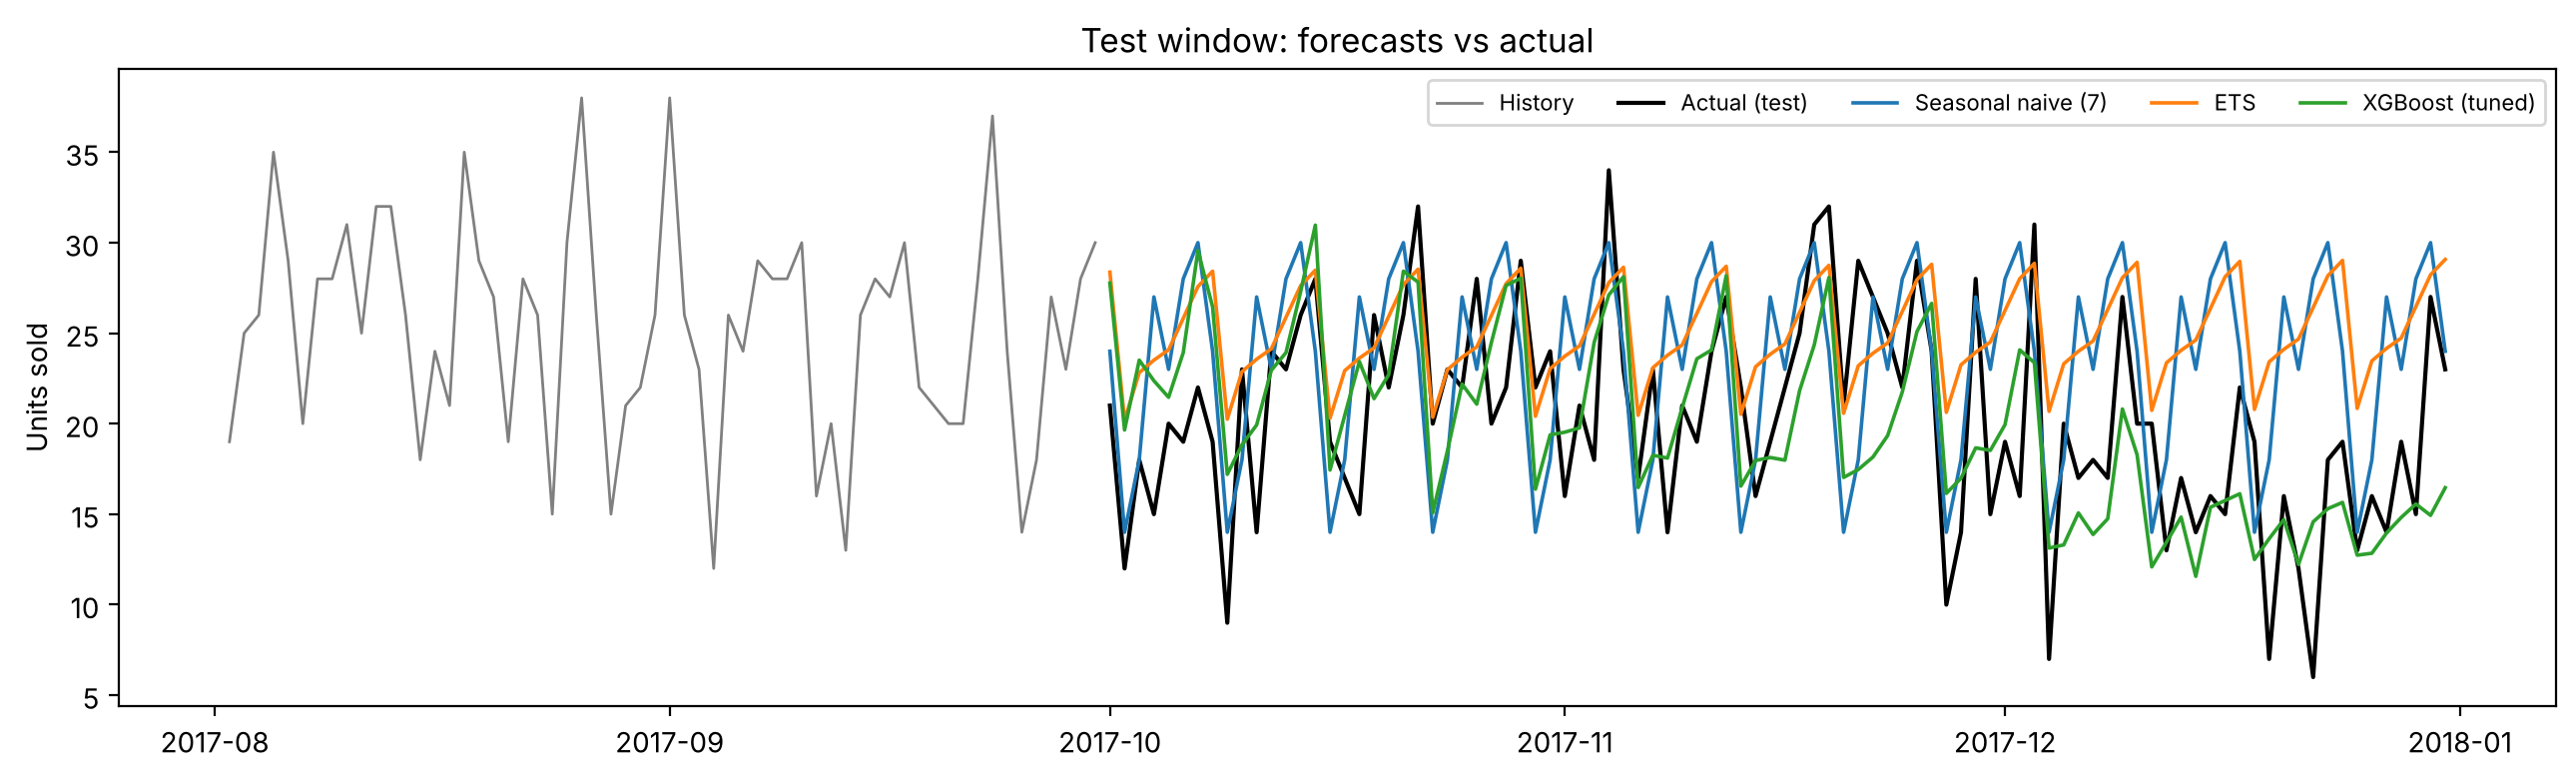

In [6]:
fig, ax = plt.subplots()
hist = train_val[-60:].to_series()
ax.plot(hist.index, hist.values, color="grey", lw=1, label="History")
ax.plot(test.time_index, test.values().flatten(), color="black", lw=1.5, label="Actual (test)")
for name in ["Seasonal naive (7)", "ETS", "XGBoost (tuned)"]:
    ax.plot(forecasts[name].time_index, forecasts[name].values().flatten(), lw=1.3, label=name)
ax.set_title("Test window: forecasts vs actual"); ax.set_ylabel("Units sold"); ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.savefig("images/model_benchmarking.png", dpi=120); plt.show()

## 6. Rolling-origin backtest with retraining

A single test window can be lucky. Here each model is retrained on an expanding window and forecasts the next 30 days, 12 times, from 2016-07-01 to 2017-06-30 (all before the validation and test windows).

In [7]:
bt_start = pd.Timestamp("2016-07-01")
bt_series = series.drop_after(pd.Timestamp(VAL_START) - pd.Timedelta(days=1))
bt_models = {
    "Seasonal naive (7)": (NaiveSeasonal(K=7), {}),
    "ETS": (ExponentialSmoothing(seasonal_periods=7), {}),
    "XGBoost (tuned)": (make_xgb(best_params, random_state=SEED), {"future_covariates": covariates}),
}
bt_rows, bt_forecasts = [], {}
for name, (model, kw) in bt_models.items():
    fcs = model.historical_forecasts(bt_series, start=bt_start, forecast_horizon=30, stride=30,
                                     retrain=True, last_points_only=False, verbose=False, **kw)
    window_mae = [float(mae(bt_series.slice_intersect(fc), fc)) for fc in fcs]
    bt_rows.append({"model": name, "windows": len(fcs), "mean_MAE": np.mean(window_mae), "std_MAE": np.std(window_mae)})
    bt_forecasts[name] = fcs

backtest = pd.DataFrame(bt_rows).set_index("model").sort_values("mean_MAE")
backtest.round(2)

,windows,mean_MAE,std_MAE
model,,,
XGBoost (tuned),12,4.17,0.60
ETS,12,4.20,0.83
Seasonal naive (7),12,5.18,0.95


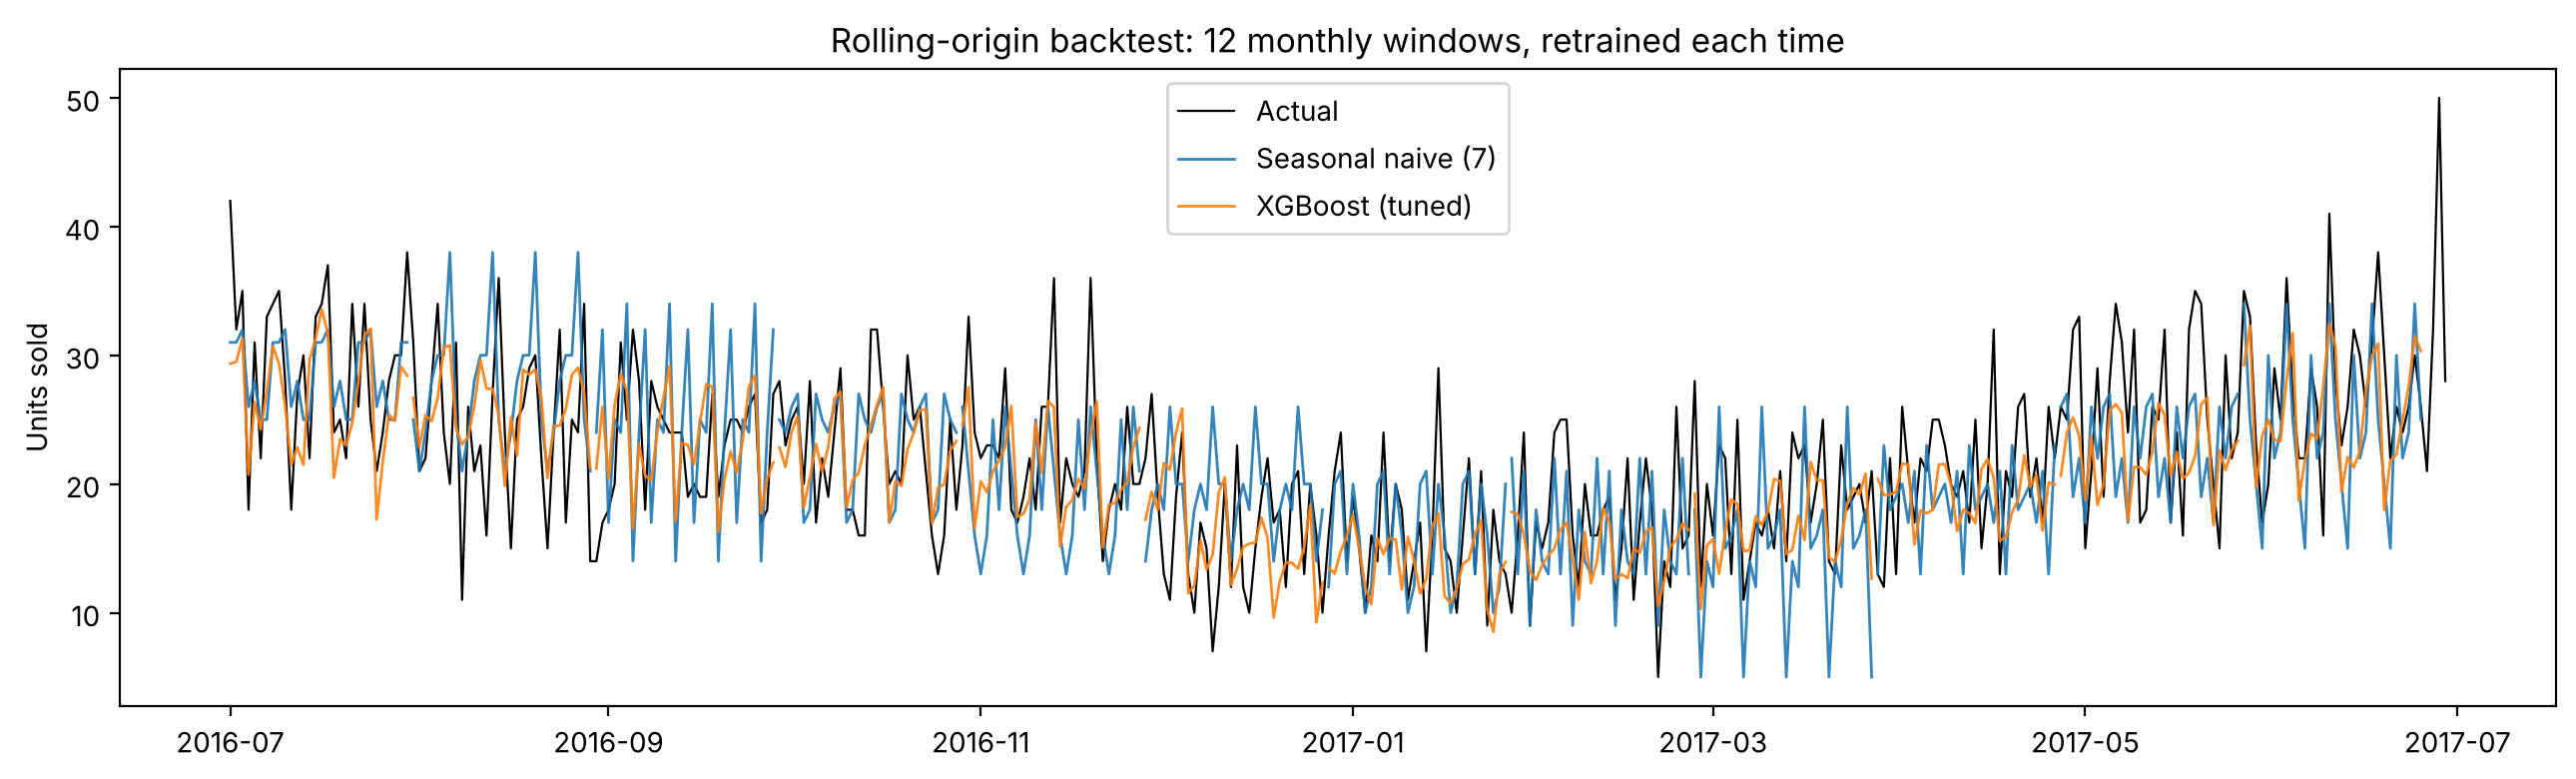

In [8]:
fig, ax = plt.subplots()
actual = bt_series.drop_before(bt_start - pd.Timedelta(days=1)).to_series()
ax.plot(actual.index, actual.values, color="black", lw=0.8, label="Actual")
for name in ["Seasonal naive (7)", "XGBoost (tuned)"]:
    for i, fc in enumerate(bt_forecasts[name]):
        ax.plot(fc.time_index, fc.values().flatten(), lw=1, color="C1" if "XGB" in name else "C0",
                alpha=0.9, label=name if i == 0 else None)
ax.set_title("Rolling-origin backtest: 12 monthly windows, retrained each time"); ax.set_ylabel("Units sold"); ax.legend()
plt.tight_layout(); plt.savefig("images/1y_backtest.png", dpi=120); plt.show()

## 7. Final model and explainability (SHAP)

The production model is refitted on the full history (2013–2017), so the app forecasts genuinely future dates. SHAP values show which inputs drive the one-day-ahead forecast.

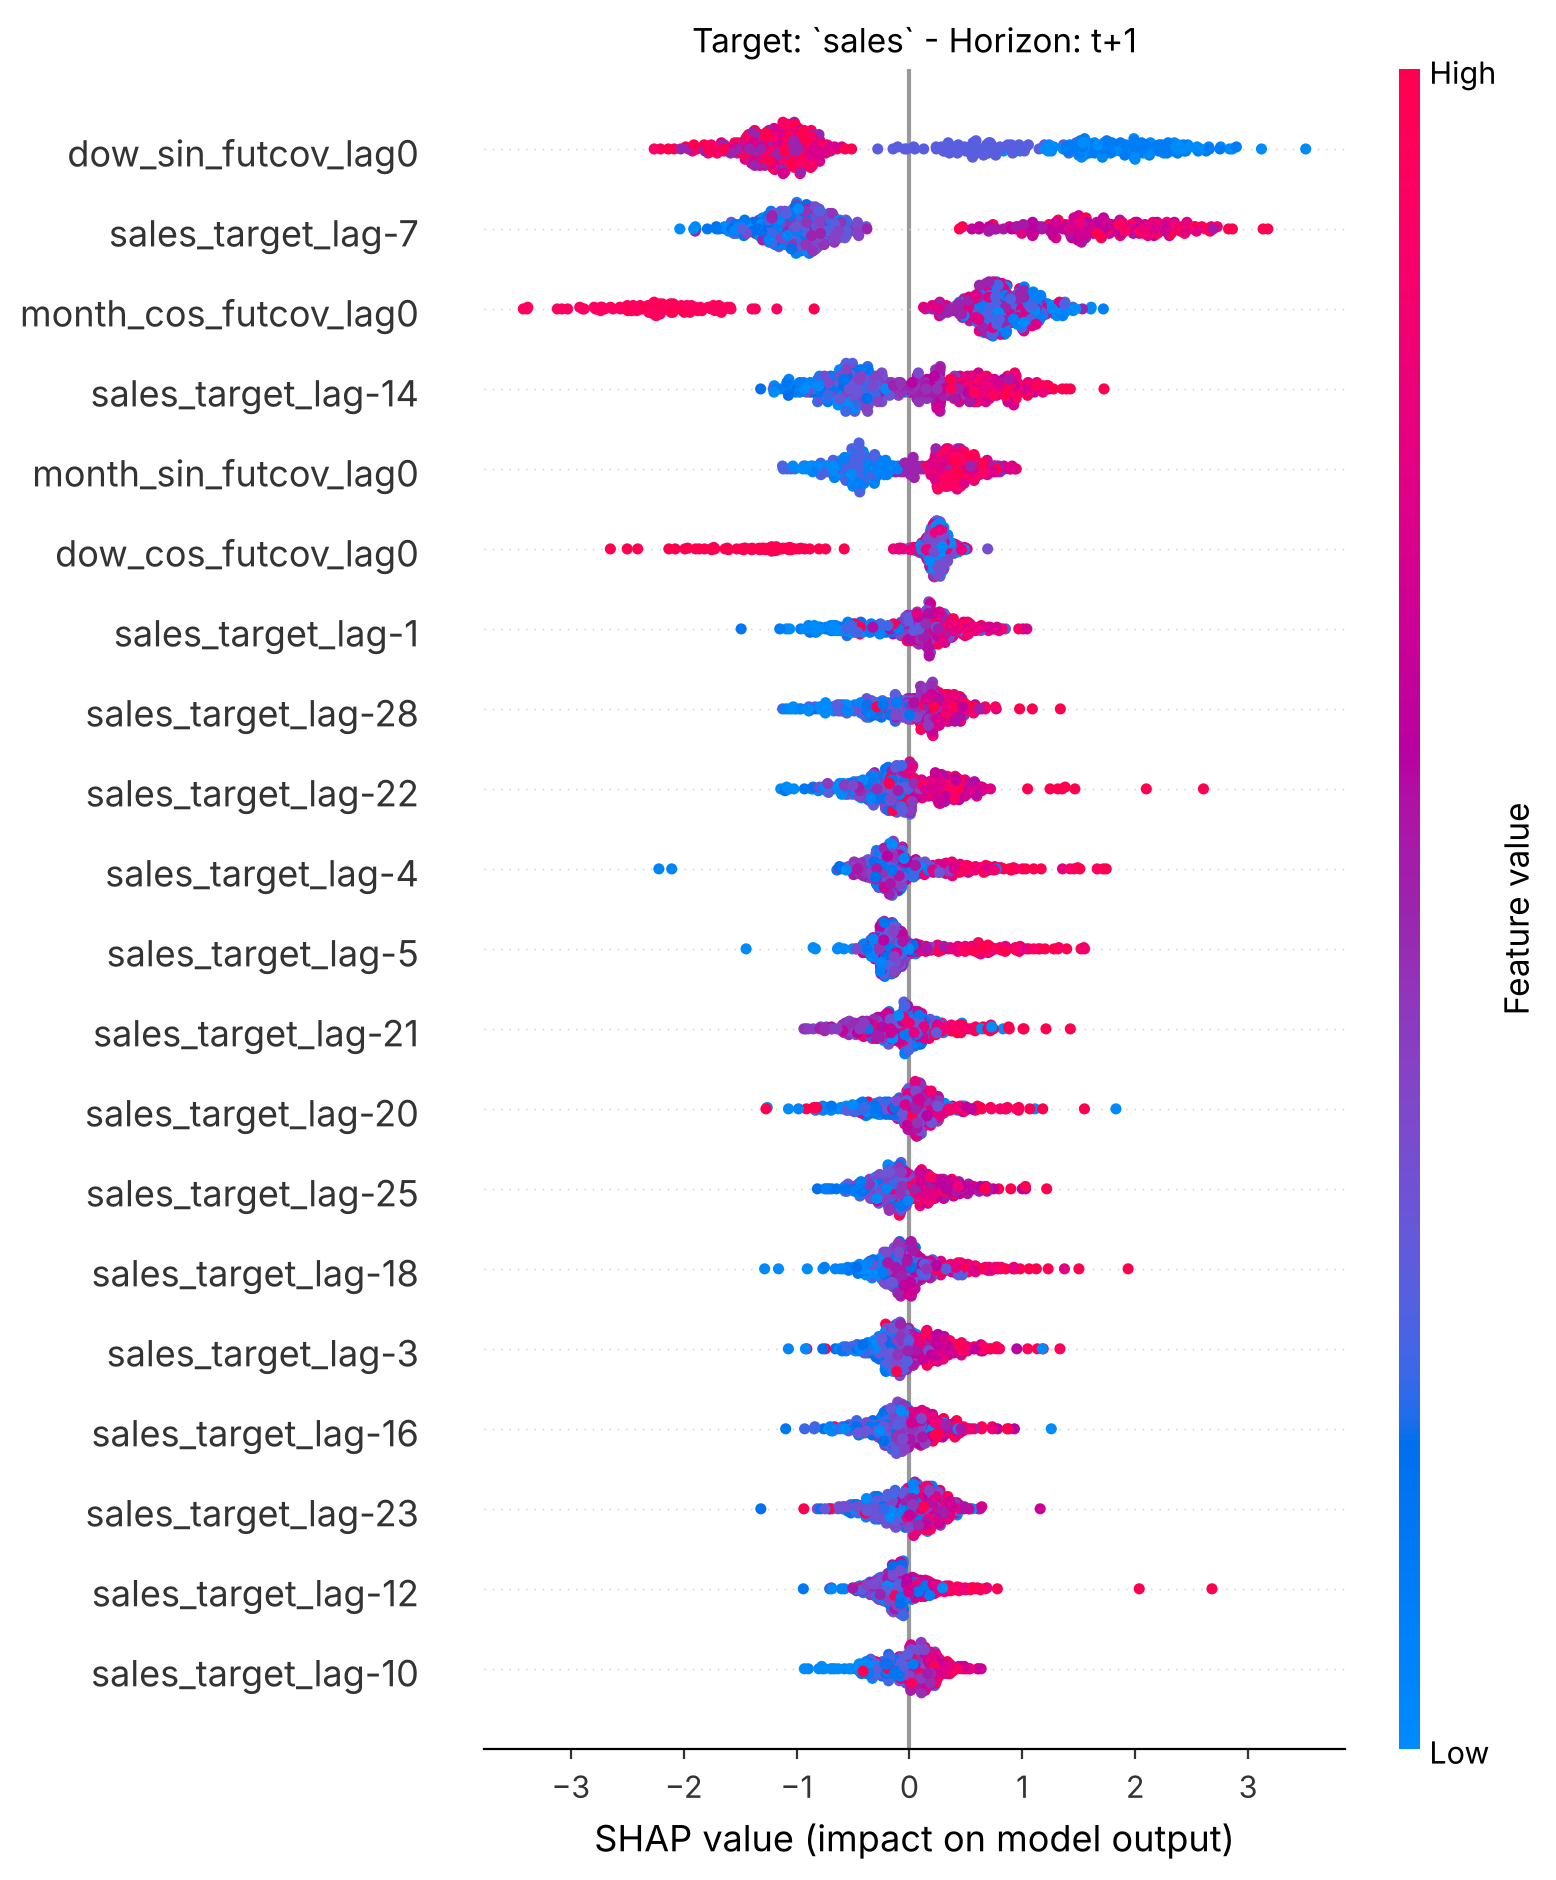

In [9]:
final_model = make_xgb(best_params, random_state=SEED)
final_model.fit(series, future_covariates=covariates)

explainer = ShapExplainer(final_model)
_ = explainer.summary_plot(horizons=[1], num_samples=500)

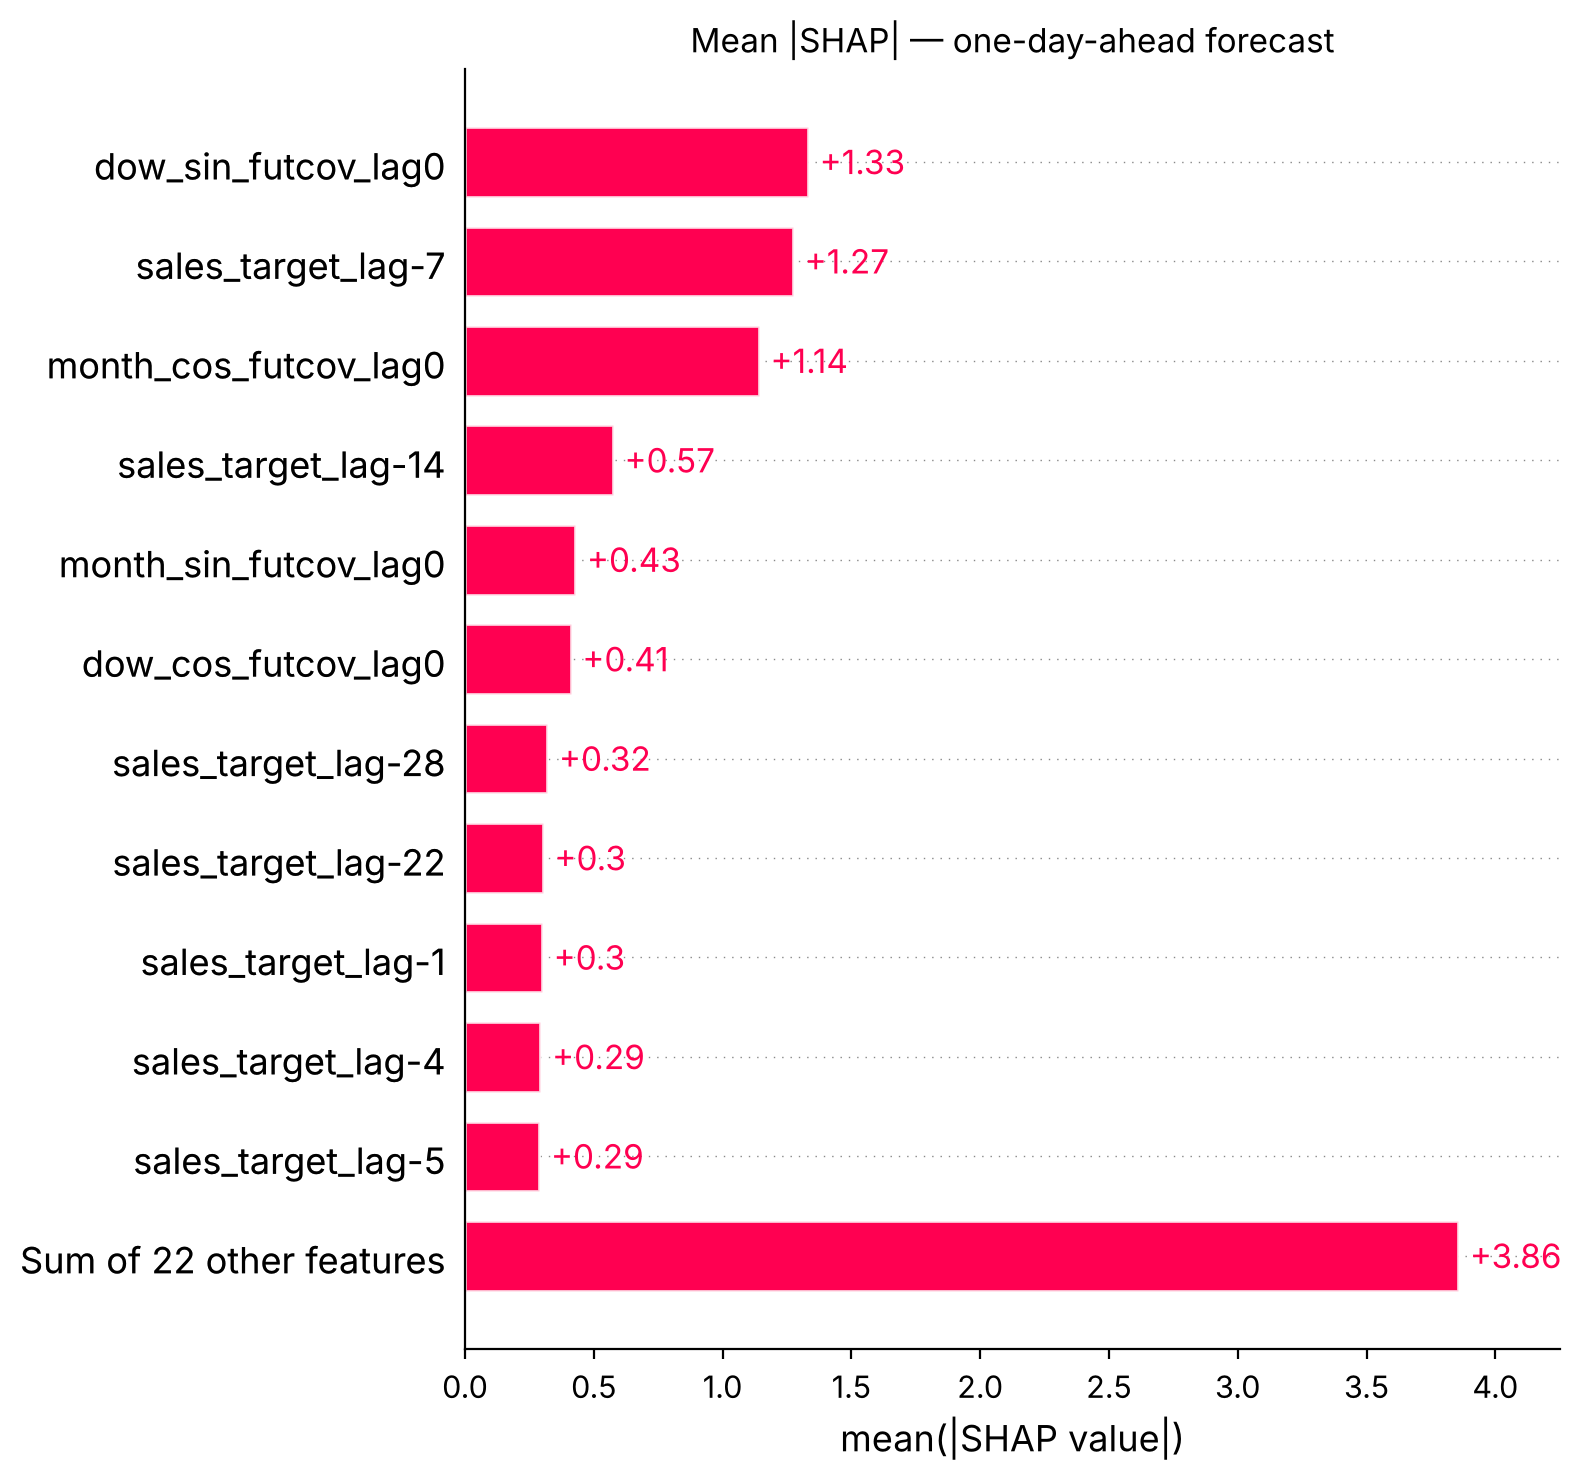

In [10]:
import shap
res = explainer.explain()
shap_vals = res.get_shap_explanation_object(horizon=1)
plt.figure()
shap.plots.bar(shap_vals, max_display=12, show=False)
plt.title("Mean |SHAP| — one-day-ahead forecast")
plt.tight_layout(); plt.savefig("images/shap_importance.png", dpi=120, bbox_inches="tight"); plt.show()

In [11]:
joblib.dump({"model": final_model, "params": best_params, "store": STORE, "item": ITEM},
            "models/xgb_final_model.joblib", compress=3)
series.to_dataframe().reset_index().rename(columns={"time": "date"}).to_csv("data/history.csv", index=False)
print("Saved models/xgb_final_model.joblib and data/history.csv")

Saved models/xgb_final_model.joblib and data/history.csv


## 8. Conclusions and limitations

- On the test window (Oct–Dec 2017) tuned XGBoost has the lowest error. Its advantage comes largely from the month covariates, which capture the yearly drop in demand that seasonal naive, ETS and AutoARIMA (weekly seasonality only) miss; SHAP confirms that calendar features and the 7-day lag drive the forecast.
- In the rolling-origin backtest over the preceding year, XGBoost and ETS are essentially tied and both clearly beat seasonal naive. A single test window overstates XGBoost's advantage.
- Hyperparameters were selected on the validation window only; the test window was used once.
- Limitations: a single store–item series; point forecasts without prediction intervals; no holiday or promotion covariates are available in this dataset.